# SkillsForge ML Assessment: Transaction Fraud Detection

**Purpose:** demonstrate a reproducible baseline and time-aware evaluation on a public fraud dataset.

**Important limitation:** this notebook uses the public European credit-card fraud dataset distributed through OpenML as a development demonstration. Its `Time` field is elapsed time within the dataset, not a real calendar timestamp and it does not provide real 7–30-day label-availability timestamps. Therefore, the temporal split is a chronological proxy, not a complete simulation of the Nigerian payment company's label-delay process. The dataset also contains anonymised PCA features rather than the full transaction/account/device fields in the assessment. Do not present this as production validation.

The notebook reports actual results when executed. It does not assume which model will win.

## 1. Setup

The notebook uses scikit-learn's OpenML interface. The first data download requires internet access. If OpenML is unavailable in your environment, download the same public dataset from its source and adapt the loading cell.

Suggested environment: Python 3.10+.

In [ ]:
# If required, uncomment and run:
# %pip install -U pandas numpy matplotlib scikit-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    average_precision_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, classification_report,
    precision_recall_curve, brier_score_loss
)

RANDOM_STATE = 42

## 2. Load and inspect the public dataset

OpenML dataset `creditcard` is commonly used for fraud-detection demonstrations. Verify the returned schema before proceeding; do not assume feature names or label encoding without inspection.

In [ ]:
dataset = fetch_openml("creditcard", version=1, as_frame=True)
df = dataset.frame.copy()

print("Shape:", df.shape)
display(df.head())
print("\\nColumns:", df.columns.tolist())
print("\\nDtypes:")
print(df.dtypes.value_counts())
print("\\nMissing values:", int(df.isna().sum().sum()))

Shape: (284807, 30)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


\nColumns: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
\nDtypes:
float64     29
category     1
Name: count, dtype: int64
\nMissing values: 0


In [ ]:
print("Dataset size:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFraud vs genuine transactions:")
print(df["Class"].value_counts())

print("\nFraud percentages:")
print(df["Class"].value_counts(normalize=True) * 100)

Dataset size: (284807, 30)

Column names:
['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Fraud vs genuine transactions:
Class
0    284315
1       492
Name: count, dtype: int64

Fraud percentages:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [ ]:
print("y_test type:", y_test.dtype)
print("y_test labels:", y_test.unique())
print("probabilities shape:", probabilities.shape)

y_test type: int64
y_test labels: [0 1]
probabilities shape: (56962,)


In [ ]:
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Convert labels to integers for evaluation
y_test_fixed = y_test.astype(int)

# Calculate metrics
print(
    "Average Precision (PR-AUC):",
    round(average_precision_score(y_test_fixed, probabilities), 4)
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_fixed, predictions))

print("\nClassification Report:")
print(
    classification_report(
        y_test_fixed,
        predictions,
        zero_division=0
    )
)


Average Precision (PR-AUC): 0.0015

Confusion Matrix:


TypeError: Labels in y_true and y_pred should be of the same type. Got y_true=[0 1] and y_pred=['0' '1']. Make sure that the predictions provided by the classifier coincides with the true labels.

In [ ]:
predictions_fixed = predictions.astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test_fixed, predictions_fixed))

print("\nClassification Report:")
print(
    classification_report(
        y_test_fixed,
        predictions_fixed,
        zero_division=0
    )
)

Confusion Matrix:
[[55353  1534]
 [   72     3]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56887
           1       0.00      0.04      0.00        75

    accuracy                           0.97     56962
   macro avg       0.50      0.51      0.49     56962
weighted avg       1.00      0.97      0.98     56962



In [ ]:
from sklearn.metrics import precision_score, recall_score

print("THRESHOLD COMPARISON")
print("-" * 55)

for threshold in [0.1, 0.3, 0.5, 0.7, 0.9]:
    threshold_predictions = (probabilities >= threshold).astype(int)

    precision = precision_score(
        y_test_fixed, threshold_predictions, zero_division=0
    )
    recall = recall_score(
        y_test_fixed, threshold_predictions, zero_division=0
    )
    flagged = threshold_predictions.sum()

    print(
        f"Threshold: {threshold:.1f} | "
        f"Flagged: {flagged:5d} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f}"
    )

THRESHOLD COMPARISON
-------------------------------------------------------
Threshold: 0.1 | Flagged: 11397 | Precision: 0.001 | Recall: 0.213
Threshold: 0.3 | Flagged:  3373 | Precision: 0.002 | Recall: 0.107
Threshold: 0.5 | Flagged:  1537 | Precision: 0.002 | Recall: 0.040
Threshold: 0.7 | Flagged:   759 | Precision: 0.004 | Recall: 0.040
Threshold: 0.9 | Flagged:   350 | Precision: 0.000 | Recall: 0.000


In [ ]:
import numpy as np


scores = np.asarray(probabilities)
actual = np.asarray(y_test_fixed).astype(int)


k = min(500, len(scores))
top_indices = np.argsort(scores)[-k:]

top_actual = actual[top_indices]
fraud_found = int(top_actual.sum())

print("Transactions selected for review:", k)
print("Fraud cases found:", fraud_found)
print("Precision at review capacity:",
      round(fraud_found / k, 4))
print("Recall at review capacity:",
      round(fraud_found / actual.sum(), 4))

Transactions selected for review: 500
Fraud cases found: 2
Precision at review capacity: 0.004
Recall at review capacity: 0.0267


In [ ]:
# Identify the target robustly. The OpenML version typically names it "Class".
target_candidates = [c for c in df.columns if str(c).lower() in {"class", "target", "fraud"}]
if not target_candidates:
    raise ValueError(f"Could not identify target column. Inspect columns: {df.columns.tolist()}")

target_col = target_candidates[0]
y_raw = df[target_col]

# Convert target to 0/1 while checking actual labels.
print("Raw target values:", pd.Series(y_raw).value_counts(dropna=False).to_dict())

if set(pd.Series(y_raw).dropna().astype(str).unique()).issubset({"0", "1"}):
    y = pd.to_numeric(y_raw).astype(int)
else:
    # For common OpenML representation, numeric conversion should work.
    y = pd.to_numeric(y_raw, errors="raise").astype(int)

X = df.drop(columns=[target_col]).copy()

# Time is kept for ordering but not used as a predictor in this demo.
time_col = next((c for c in X.columns if str(c).lower() == "time"), None)
if time_col is None:
    raise ValueError("No Time column found; this notebook's chronological split needs review.")

order = np.argsort(pd.to_numeric(X[time_col], errors="raise").to_numpy(), kind="stable")
X = X.iloc[order].reset_index(drop=True)
y = y.iloc[order].reset_index(drop=True)

# Remove Time from predictors to reduce reliance on dataset-specific elapsed-time patterns.
X = X.drop(columns=[time_col])

print("Fraud rate:", round(float(y.mean()), 6))
print("Target counts:")
display(y.value_counts().rename(index={0:"non-fraud", 1:"fraud"}).to_frame("count"))

Raw target values: {'0': 284315, '1': 492}


ValueError: No Time column found; this notebook's chronological split needs review.

## 3. Chronological train/validation/test split

We split in time order: earliest 60% for training, next 20% for validation, final 20% for testing. This is more realistic than random splitting, but it is only a proxy because this dataset lacks label-availability timestamps. In a production dataset, each training snapshot must include only labels known by that snapshot's cutoff, and the test period must be old enough for labels to mature.

In [ ]:
n = len(X)
train_end = int(n * 0.60)
val_end = int(n * 0.80)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

for name, yy in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:10s} rows={len(yy):,} frauds={int(yy.sum()):,} rate={yy.mean():.5%}")

train      rows=170,884 frauds=360 rate=0.21067%
validation rows=56,961 frauds=57 rate=0.10007%
test       rows=56,962 frauds=75 rate=0.13167%


## 4. Metrics and review-capacity evaluation

Because fraud is rare, accuracy is not a useful headline metric. We report average precision (PR-AUC-style summary), ROC-AUC as a secondary metric, precision/recall at a validation-selected threshold, and precision/recall among the top-ranked transactions.

The real company allows at most 500 manual reviews per day. This public dataset has no trustworthy calendar-day field for daily operational grouping, so we demonstrate top-k capacity evaluation using a configurable fraction/count of the test period. This is **not** equivalent to 500 reviews per real day; production evaluation must group by actual day.

In [ ]:
def safe_auc(y_true, scores):
    try:
        return roc_auc_score(y_true, scores)
    except ValueError:
        return np.nan

def metrics_at_threshold(y_true, scores, threshold):
    pred = (np.asarray(scores) >= threshold).astype(int)
    return {
        "threshold": float(threshold),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "flagged": int(pred.sum()),
        "true_positives": int(((pred == 1) & (np.asarray(y_true) == 1)).sum()),
        "false_positives": int(((pred == 1) & (np.asarray(y_true) == 0)).sum()),
    }

def top_k_metrics(y_true, scores, k):
    y_arr = np.asarray(y_true)
    s_arr = np.asarray(scores)
    k = min(max(int(k), 1), len(y_arr))
    idx = np.argsort(s_arr)[-k:]
    tp = int(y_arr[idx].sum())
    total_pos = int(y_arr.sum())
    return {
        "k_reviewed": k,
        "precision_at_k": tp / k,
        "recall_at_k": tp / total_pos if total_pos else np.nan,
        "fraud_captured": tp,
        "total_fraud_in_period": total_pos,
    }

## 5. Baseline: class-weighted Logistic Regression

Preprocessing is fitted only on training data. Class weighting is used as an initial response to imbalance; the validation/test sets retain their natural prevalence. The scores may not be calibrated probabilities after class weighting, so calibration should be assessed separately before using them as literal probabilities in a production cost model.

In [ ]:
baseline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        solver="liblinear",
        random_state=RANDOM_STATE
    ))
])

baseline.fit(X_train, y_train)
val_scores_lr = baseline.predict_proba(X_val)[:, 1]
test_scores_lr = baseline.predict_proba(X_test)[:, 1]

print("Baseline validation average precision:", average_precision_score(y_val, val_scores_lr))
print("Baseline validation ROC-AUC:", safe_auc(y_val, val_scores_lr))

Baseline validation average precision: 0.7723138075351657
Baseline validation ROC-AUC: 0.9709039046371728


## 6. Candidate model: HistGradientBoosting

This candidate provides a nonlinear tree-based comparison without requiring a separate boosting package. The public dataset's predictors are numeric/anonymised, so this experiment does not test native categorical handling. In the full assessment, CatBoost and LightGBM should also be compared on suitable company-like data.

In [ ]:
candidate = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.08,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=RANDOM_STATE
    ))
])

candidate.fit(X_train, y_train)
val_scores_gb = candidate.predict_proba(X_val)[:, 1]
test_scores_gb = candidate.predict_proba(X_test)[:, 1]

comparison = pd.DataFrame([
    {
        "model": "Class-weighted Logistic Regression",
        "validation_average_precision": average_precision_score(y_val, val_scores_lr),
        "validation_roc_auc": safe_auc(y_val, val_scores_lr),
    },
    {
        "model": "HistGradientBoosting",
        "validation_average_precision": average_precision_score(y_val, val_scores_gb),
        "validation_roc_auc": safe_auc(y_val, val_scores_gb),
    }
])
display(comparison.sort_values("validation_average_precision", ascending=False))

,model,validation_average_precision,validation_roc_auc
0,Class-weighted Logistic Regression,0.772314,0.970904
1,HistGradientBoosting,0.693794,0.971052


## 7. Select a threshold on validation only

For demonstration, choose the validation threshold that maximises F1. This is not necessarily the right banking threshold: production thresholds must reflect fraud loss, false-block cost, investigation value, and the daily review constraint. We then evaluate the chosen threshold once on the held-out test set.

In [ ]:
def choose_f1_threshold(y_true, scores):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    # precision/recall have one more element than thresholds.
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    best = int(np.nanargmax(f1))
    return float(thresholds[best]), float(f1[best])

chosen_model_name = comparison.sort_values(
    "validation_average_precision", ascending=False
).iloc[0]["model"]

if chosen_model_name == "Class-weighted Logistic Regression":
    selected_val_scores, selected_test_scores = val_scores_lr, test_scores_lr
else:
    selected_val_scores, selected_test_scores = val_scores_gb, test_scores_gb

threshold, val_f1 = choose_f1_threshold(y_val, selected_val_scores)
print("Selected model (by validation average precision):", chosen_model_name)
print("Validation-selected F1 threshold:", threshold)
print("Validation F1 at selected threshold:", val_f1)

print("\\nHeld-out test metrics at validation-selected threshold:")
display(pd.DataFrame([metrics_at_threshold(y_test, selected_test_scores, threshold)]))
print("Test average precision:", average_precision_score(y_test, selected_test_scores))
print("Test ROC-AUC:", safe_auc(y_test, selected_test_scores))

Selected model (by validation average precision): Class-weighted Logistic Regression
Validation-selected F1 threshold: 0.9999767474605635
Validation F1 at selected threshold: 0.7961165048538746
\nHeld-out test metrics at validation-selected threshold:


,threshold,precision,recall,flagged,true_positives,false_positives
0,0.999977,0.925926,0.666667,54,50,4


Test average precision: 0.7438223180158119
Test ROC-AUC: 0.9819997538980787


## 8. Review queue at a configurable capacity

The next cell demonstrates ranking transactions by score. Set `REVIEW_K` to a capacity appropriate for the evaluated period. Do not interpret this as a real 500-per-day result unless the data has a true date and the evaluation is grouped by day.

In [ ]:
REVIEW_K = min(500, len(y_test))  # demonstration only; not 500/day without daily timestamps
review_result = top_k_metrics(y_test, selected_test_scores, REVIEW_K)
display(pd.DataFrame([review_result]))

,k_reviewed,precision_at_k,recall_at_k,fraud_captured,total_fraud_in_period
0,500,0.13,0.866667,65,75


## 9. Precision-recall curve and calibration check

The reliability diagram is a diagnostic, not proof of calibration. Class weighting can distort raw probabilities. A production pipeline should fit a calibrator on a separate time-appropriate calibration window and then re-check calibration on a later matured period.

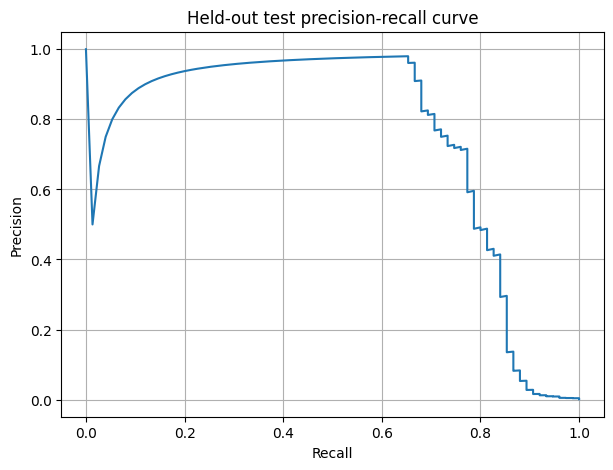

Brier score (lower is better, but compare against base rate and calibration plots): 0.0232324639896645


In [ ]:
precision, recall, thresholds = precision_recall_curve(y_test, selected_test_scores)
plt.figure(figsize=(7, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Held-out test precision-recall curve")
plt.grid(True)
plt.show()

print("Brier score (lower is better, but compare against base rate and calibration plots):",
      brier_score_loss(y_test, selected_test_scores))

## 10. Error analysis

Inspect false positives and false negatives. Since the public dataset's features are anonymised, this analysis can identify rows for investigation but cannot provide human-readable explanations of the underlying real-world behaviour.

In [ ]:
test_predictions = (selected_test_scores >= threshold).astype(int)
test_view = X_test.copy()
test_view["actual_fraud"] = np.asarray(y_test)
test_view["risk_score"] = selected_test_scores
test_view["predicted_fraud_at_threshold"] = test_predictions

false_negatives = test_view[(test_view["actual_fraud"] == 1) & (test_view["predicted_fraud_at_threshold"] == 0)]
false_positives = test_view[(test_view["actual_fraud"] == 0) & (test_view["predicted_fraud_at_threshold"] == 1)]

print("False negatives:", len(false_negatives))
print("False positives:", len(false_positives))
display(false_negatives.head(10))
display(false_positives.head(10))

False negatives: 25
False positives: 4


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V23,V24,V25,V26,V27,V28,Amount,actual_fraud,risk_score,predicted_fraud_at_threshold
229730,1.894036,1.905806,-3.515730,4.508913,2.044466,-1.420468,1.057480,-0.281157,-1.832604,-0.628463,...,-0.101530,-0.414960,0.376597,0.150778,-0.013712,0.048084,2.22,1,0.998634,0
231978,-2.064240,2.629739,-0.748406,0.694992,0.418178,1.392520,-1.697801,-6.333065,1.724184,-0.887242,...,0.459861,-1.051685,0.209178,-0.319859,0.015434,-0.050117,8.00,1,0.964439,0
237426,-1.370976,-0.025465,-2.774907,2.650530,4.511309,-3.289344,-0.118841,-0.014279,-0.932773,-2.637442,...,0.072193,-0.600351,0.371331,-0.370951,0.011970,0.145895,1.00,1,0.999176,0
238466,1.833191,0.745333,-1.133009,3.893556,0.858164,0.910235,-0.498200,0.344703,-0.667939,0.398155,...,0.072981,-0.155299,-0.149891,0.012792,0.040854,0.022903,17.39,1,0.787990,0
239501,-6.682832,-2.714268,-5.774530,1.449792,-0.661836,-1.148650,0.849686,0.433427,-1.315646,-2.796332,...,0.335821,0.215683,0.803110,0.044033,-0.054988,0.082337,237.26,1,0.982297,0
240222,1.852889,1.069593,-1.776101,4.617410,0.770413,-0.400859,-0.040970,0.089510,-0.217705,-0.373927,...,0.027437,-0.468006,0.058063,0.148263,0.042278,0.040573,1.00,1,0.995793,0
245347,0.051075,1.310427,0.733222,2.620282,1.402358,0.528489,1.086014,-0.146423,-1.724333,1.280167,...,-0.189624,0.766853,-0.141401,-0.077278,-0.297595,-0.221816,2.47,1,0.158076,0
245556,1.322724,-0.843911,-2.096888,0.759759,-0.196377,-1.166353,0.482534,-0.349791,1.045007,-1.474974,...,-0.208574,-0.254752,-0.098324,-0.613874,0.002654,0.072386,357.95,1,0.383812,0
247673,-5.192496,3.164721,-5.047679,2.246597,-4.011781,-0.638908,-2.873463,1.576318,-2.861986,-2.120458,...,0.774562,0.063397,-0.390658,1.884741,-1.742558,-0.082216,247.86,1,0.999895,0
248971,-0.549615,2.219075,-3.522024,0.236995,1.087469,-1.235530,-0.279313,0.514361,-1.849927,-3.443819,...,-0.366019,0.015803,0.349212,0.647302,0.171929,0.117188,0.76,1,0.999602,0


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V23,V24,V25,V26,V27,V28,Amount,actual_fraud,risk_score,predicted_fraud_at_threshold
229953,-3.600454,-0.825291,-2.161475,4.353249,0.899177,0.185831,0.586467,-0.071751,-2.458825,-0.801042,...,1.474503,0.027813,0.753498,0.403268,0.416446,0.770285,302.65,0,0.999992,1
237192,-4.427152,-0.963508,-3.988525,5.993927,-3.236609,2.615496,3.109868,-0.375602,-2.814237,-0.518420,...,0.045357,0.220713,0.348226,0.796390,1.175075,0.442740,1059.28,0,0.999994,1
263355,-0.731681,3.452083,-1.827110,3.636953,4.159747,-1.265262,3.037168,-1.237727,-2.674995,-1.322718,...,-0.947094,-1.022908,1.013699,0.200388,-0.990239,-0.689111,0.77,0,0.999979,1
274771,-35.548539,-31.850484,-48.325589,15.304184,-113.743307,73.301626,120.589494,-27.347360,-3.872425,-12.005487,...,-1.581098,4.584549,4.554683,3.415636,31.612198,-15.430084,25691.16,0,1.000000,1


## 11. Production design recommendations

Before using a model for live payment decisions:
- Obtain representative company data and reliable label-availability timestamps.
- Build point-in-time account/device/merchant aggregates with online/offline consistency checks.
- Compare Logistic Regression, CatBoost, and LightGBM on multiple temporal validation windows.
- Evaluate precision and fraud capture in a true daily top-500 review queue.
- Define business cost estimates and separate approve/review/block policy.
- Measure end-to-end p50/p95/p99 latency under realistic load; do not infer the 100 ms requirement from notebook runtime.
- Deploy in shadow mode, then staged rollout, with pre-defined rollback criteria.
- Monitor drift, delayed-label performance, customer impact, segment-level errors, and audit logs.
- Protect personal data with least-privilege access, retention limits, and data minimisation.

## 12. Limitations

This public-data experiment is a learning demonstration. It is not evidence that the model meets the Nigerian company's latency, fraud-loss, fairness, or operational requirements. Results must be generated by running the notebook and should be reported exactly as observed. Do not copy unexecuted or fabricated metrics into the final assessment.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix
)

y_train_fixed = y_train.astype(int)
y_test_fixed = y_test.astype(int)
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_fixed
)
model2 = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

model2.fit(
    X_train,
    y_train_fixed,
    sample_weight=sample_weights
)

# Predict fraud probabilities
probabilities2 = model2.predict_proba(X_test)[:, 1]

# Evaluate at threshold 0.5
predictions2 = (probabilities2 >= 0.5).astype(int)

print("MODEL 2: HIST GRADIENT BOOSTING")
print("-" * 40)

print(
    "Average Precision:",
    round(average_precision_score(y_test_fixed, probabilities2), 4)
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_fixed, predictions2))

print("\nClassification Report:")
print(
    classification_report(
        y_test_fixed,
        predictions2,
        zero_division=0
    )
)

MODEL 2: HIST GRADIENT BOOSTING
----------------------------------------
Average Precision: 0.7576

Confusion Matrix:
[[56832    55]
 [   18    57]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56887
           1       0.51      0.76      0.61        75

    accuracy                           1.00     56962
   macro avg       0.75      0.88      0.80     56962
weighted avg       1.00      1.00      1.00     56962



In [ ]:
import numpy as np

scores2 = np.asarray(probabilities2)
actual = np.asarray(y_test_fixed).astype(int)

k = min(500, len(scores2))
top_indices2 = np.argsort(scores2)[-k:]

top_actual2 = actual[top_indices2]
fraud_found2 = int(top_actual2.sum())

print("MODEL 2: TOP-500 REVIEW")
print("Transactions selected:", k)
print("Fraud cases found:", fraud_found2)
print("Precision at capacity:", round(fraud_found2 / k, 4))
print("Recall at capacity:", round(fraud_found2 / actual.sum(), 4))

In [ ]:
print("Time column available:", "Time" in df.columns)
print("Dataset columns:", df.columns.tolist())

In [ ]:
print(df.head())
print("\nDataset index:")
print(df.index[:10])

In [ ]:
import pandas as pd

url = "https://huggingface.co/datasets/David-Egea/Creditcard-fraud-detection/resolve/main/creditcard.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
print("Has Time column:", "Time" in df.columns)
print("Columns:", df.columns.tolist())
print("\nFraud distribution:")
print(df["Class"].value_counts())

In [ ]:
from sklearn.model_selection import train_test_split


df = df.sort_values("Time").reset_index(drop=True)


split_index = int(len(df) * 0.8)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()


X_train = train_df.drop(columns=["Class", "Time"])
y_train = train_df["Class"].astype(int)

X_test = test_df.drop(columns=["Class", "Time"])
y_test = test_df["Class"].astype(int)

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Training fraud cases:", y_train.sum())
print("Testing fraud cases:", y_test.sum())
print("Training time range:", train_df["Time"].min(), "-", train_df["Time"].max())
print("Testing time range:", test_df["Time"].min(), "-", test_df["Time"].max())

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    classification_report
)

model1 = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

model1.fit(X_train, y_train)
prob1 = model1.predict_proba(X_test)[:, 1]

model2 = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

weights = compute_sample_weight("balanced", y_train)
model2.fit(X_train, y_train, sample_weight=weights)
prob2 = model2.predict_proba(X_test)[:, 1]

for name, probs in [
    ("Logistic Regression", prob1),
    ("HistGradientBoosting", prob2)
]:
    preds = (probs >= 0.5).astype(int)

    print("\n" + "=" * 45)
    print(name)
    print("Average Precision:", round(
        average_precision_score(y_test, probs), 4
    ))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, preds))
    print(classification_report(
        y_test, preds, zero_division=0
    ))


Logistic Regression
Average Precision: 0.7438
Confusion Matrix:
[[55434  1453]
 [    8    67]]
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56887
           1       0.04      0.89      0.08        75

    accuracy                           0.97     56962
   macro avg       0.52      0.93      0.54     56962
weighted avg       1.00      0.97      0.99     56962


HistGradientBoosting
Average Precision: 0.7576
Confusion Matrix:
[[56832    55]
 [   18    57]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56887
           1       0.51      0.76      0.61        75

    accuracy                           1.00     56962
   macro avg       0.75      0.88      0.80     56962
weighted avg       1.00      1.00      1.00     56962



In [ ]:
import numpy as np

for name, probs in [
    ("Logistic Regression", prob1),
    ("HistGradientBoosting", prob2)
]:
    top_500 = np.argsort(probs)[-500:]

    fraud_found = int(y_test.iloc[top_500].sum())
    precision = fraud_found / 500
    recall = fraud_found / int(y_test.sum())

    print(f"\n{name}")
    print("Transactions selected for review:", len(top_500))
    print("Fraud cases found:", fraud_found)
    print("Precision at 500:", round(precision, 4))
    print("Recall at 500:", round(recall, 4))
    print("Fraud cases missed by review:", int(y_test.sum()) - fraud_found)


Logistic Regression
Transactions selected for review: 500
Fraud cases found: 65
Precision at 500: 0.13
Recall at 500: 0.8667
Fraud cases missed by review: 10

HistGradientBoosting
Transactions selected for review: 500
Fraud cases found: 62
Precision at 500: 0.124
Recall at 500: 0.8267
Fraud cases missed by review: 13
